In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import animation
from mpl_toolkits.mplot3d import axes3d

Partiendo del potencial de dipolo magnetico
$$
p(t) = p_0 cos(wt) \hat{z}
$$

Se consiguen los siguientes potenciales magneticos y Electricos

$$
\vec{E} = -\frac{\mu _0 p_0 w^2}{4 \pi}(\frac{sen\theta}{r}) cos(w(t-rc)) \hat{\theta}
$$

$$
\vec{B} = -\frac{\mu _0 p_0 w^2}{4 \pi c}(\frac{sen\theta}{r}) cos(w(t-rc)) \hat{\phi}
$$

In [3]:
#Constantes
mu0 = 4 * np.pi * 1e-7  # Permeabilidad del vacío (H/m)
p0 = 1
c = 3e8  # Velocidad de la luz (m/s)
lam = 1.0    
frec = c/lam              # longitud de onda (m)
w = 2 * np.pi * frec    # frecuencia angular (rad/s)
T = 2 * np.pi / w           # período (s)

In [4]:
def Campo_E(r, ang, t):
    return -p0 * mu0 * w**2 / (4 * np.pi * r) * np.sin(ang) * np.cos(w * (t - r/c))

def Campo_B(r, ang, t):
    return -p0 * mu0 * w**2 / (4 * np.pi * r*c) * np.sin(ang) * np.sin(w * (t - r/c))

In [5]:
x = np.linspace(-10, 10, 100)
z = np.linspace(-10, 10, 100)
y = np.linspace(-10, 10, 100)

t = np.linspace(0.0, 10, 10)  # Tiempo (s)


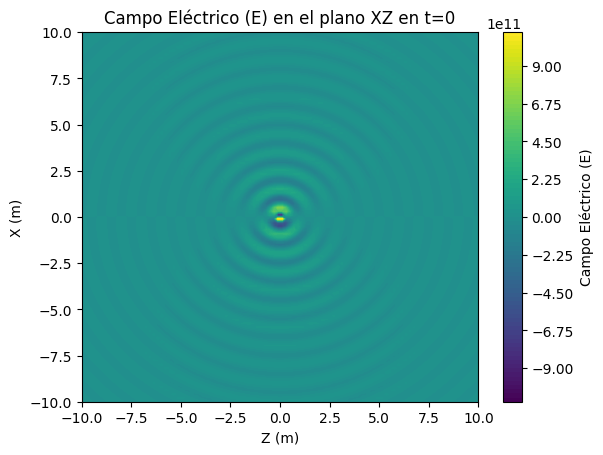

In [6]:
X2, Z2 = np.meshgrid(x, z)
r2 = np.sqrt(X2**2 + Z2**2)
theta2 = np.arctan2(Z2, X2)

plt.contourf(X2, Z2, Campo_E(r2, theta2, t[0]), levels=100, cmap='viridis')
plt.xlabel('Z (m)')
plt.ylabel('X (m)')
plt.title('Campo Eléctrico (E) en el plano XZ en t=0')
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.colorbar(label='Campo Eléctrico (E)')
plt.show()

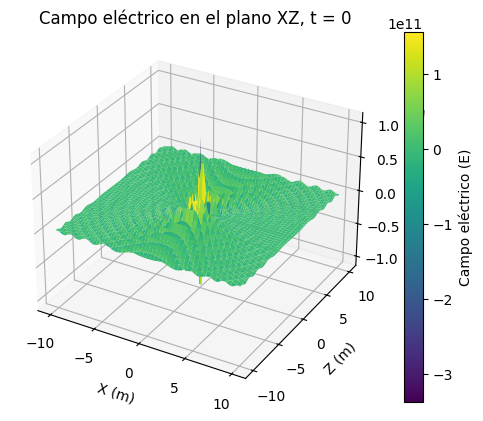

In [7]:
X2, Z2 = np.meshgrid(x, z)
r2 = np.sqrt(X2**2 + Z2**2)
theta2 = np.arctan2(Z2, X2)

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
surface = ax.plot_surface(X2, Z2, Campo_E(r2, theta2, t[0]), cmap="viridis", edgecolor="none")

ax.set_xlabel("X (m)")
ax.set_ylabel("Z (m)")
ax.set_zlabel("Campo eléctrico (E)")
ax.set_title("Campo eléctrico en el plano XZ, t = 0")
fig.colorbar(surface, ax=ax, label="Campo eléctrico (E)")

plt.show()

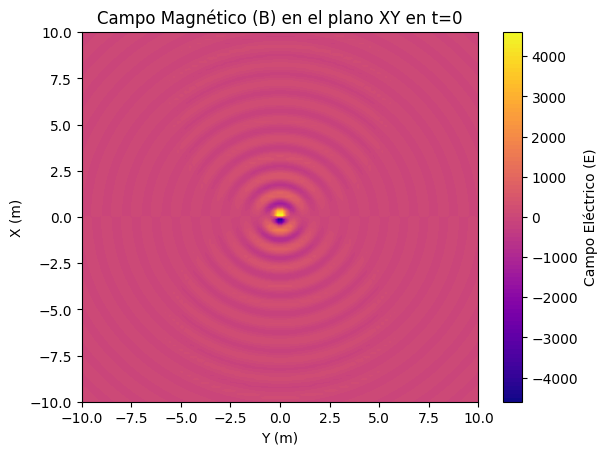

In [8]:
X, Y = np.meshgrid(x, y)
r = np.sqrt(X**2 + Y**2)
theta = np.arctan2(Y, X)

plt.contourf(X, Y, Campo_B(r, theta, t[0]), levels=100, cmap='plasma')
plt.xlabel('Y (m)')
plt.ylabel('X (m)')
plt.title('Campo Magnético (B) en el plano XY en t=0')
plt.xlim(-10, 10)
plt.ylim(-10, 10)
plt.colorbar(label='Campo Eléctrico (E)')
plt.show()

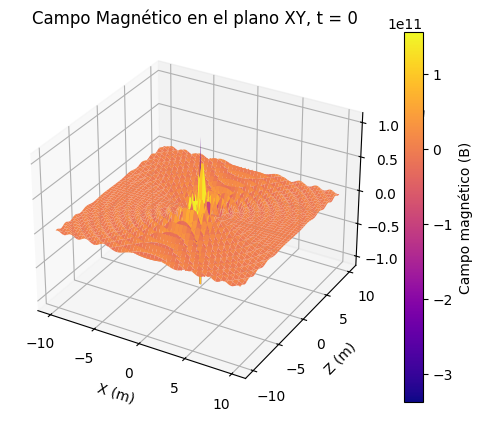

In [9]:
X3, Z3 = np.meshgrid(x, y)
r3 = np.sqrt(X3**2 + Z3**2)
theta3 = np.arctan2(Z3, X3 )

fig, ax = plt.subplots(subplot_kw={"projection": "3d"})
surface = ax.plot_surface(X3, Z3, Campo_E(r3, theta3, t[0]), cmap="plasma", edgecolor="none")

ax.set_xlabel("X (m)")
ax.set_ylabel("Z (m)")
ax.set_zlabel("Campo magnético (B)")
ax.set_title("Campo Magnético en el plano XY, t = 0")
fig.colorbar(surface, ax=ax, label="Campo magnético (B)")
plt.show()

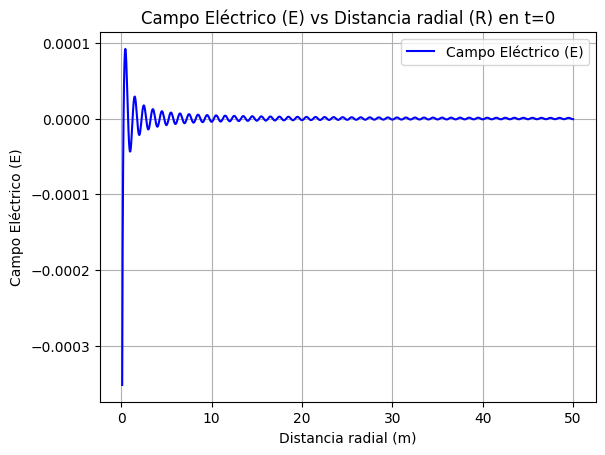

In [10]:
Theta = np.pi
R = np.linspace(0.1, 50, 1000)  # Distancia radial (m)
plt.plot(R, Campo_E(R, Theta, t[0]), label='Campo Eléctrico (E)', color='blue')
plt.xlabel('Distancia radial (m)')
plt.ylabel('Campo Eléctrico (E)')

plt.title('Campo Eléctrico (E) vs Distancia radial (R) en t=0')
plt.legend()
plt.grid(True)
plt.show()


El vector de Poynting es:

$$
\vec{S}(r,t) = \frac{\mu _0}{c}({\frac{p_0 w^2}{4 \pi}(\frac{sen(\theta)}{r})cos[w(t-\frac{r}{c})]})^2 \hat{r}
$$
y
$$
<S> = (\frac{\mu _0 p_0^2 w^4}{32 \pi^2 c}) \frac{sen^2(\theta)}{r^2} \hat{r}
$$


In [30]:
def Poynting_vector(r, ang, t):
    E = Campo_E(r, ang, t)
    B = Campo_B(r, ang, t)
    #El campo electrico y magnético son perpendiculares, por lo que el vector de Poynting es simplemente el producto de sus magnitudes dividido por la permeabilidad del vacío.
    return (1/mu0) * E * B

#Promedio de la magnitud del vector de Poynting sobre un ciclo completo
def avg_magPoynting(r, theta, T):
    # Integrar la magnitud del vector de Poynting sobre un ciclo completo y dividir por el período
    t = np.linspace(0, T, 1000)  # Tiempo (s)
    S = Poynting_vector(r, theta, t)
    avg_S = np.trapezoid(S, t) / T
    return np.abs(avg_S)

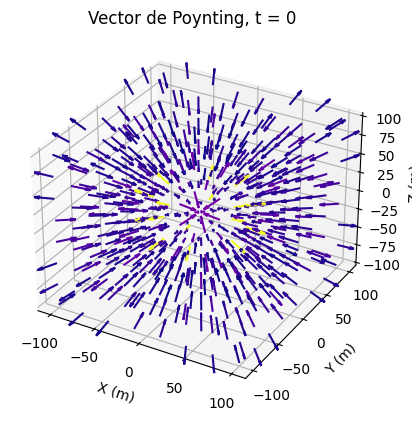

In [23]:
Xq, Yq, Zq = np.meshgrid(np.linspace(-100, 100, 8), np.linspace(-100, 100, 8), np.linspace(-100, 100, 8))

rq = np.sqrt(Xq**2 + Yq**2 + Zq**2) 
valid = rq > 0  

theta_q = np.arccos(np.clip(Zq[valid] / rq[valid], -1, 1))
S_q = Poynting_vector(rq[valid], theta_q, t[0])


U = S_q * Xq[valid] / rq[valid]
V = S_q * Yq[valid] / rq[valid]
W = S_q * Zq[valid] / rq[valid]

#Colores a partir de la magnitud del vector de Poynting recomendado por el copiloto
magnitude = np.abs(S_q)
color_values = (magnitude - magnitude.min()) / (np.ptp(magnitude) or 1)
colors = plt.cm.plasma(color_values)

fig = plt.figure()
ax3d = fig.add_subplot(111, projection="3d")
ax3d.quiver(
    Xq[valid], Yq[valid], Zq[valid], U, V, W,
    length=20, normalize=True, colors=colors
)

ax3d.set_xlabel("X (m)")
ax3d.set_ylabel("Y (m)")
ax3d.set_zlabel("Z (m)")
ax3d.set_title(f"Vector de Poynting, t = 0 ")
plt.show()

In [66]:

def avg_magPoynting(r, theta):
    r, theta = np.broadcast_arrays(np.asarray(r), np.asarray(theta))
    return (mu0 * p0**2 * w**4 / (32 * np.pi**2 * c**3)
            * np.sin(theta)**2 / r**2)

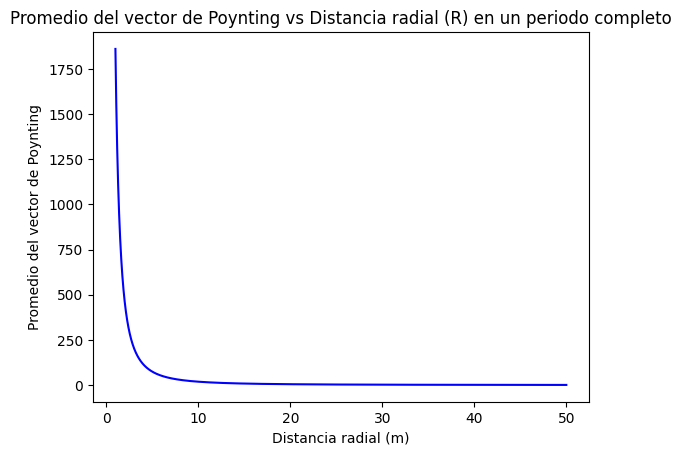

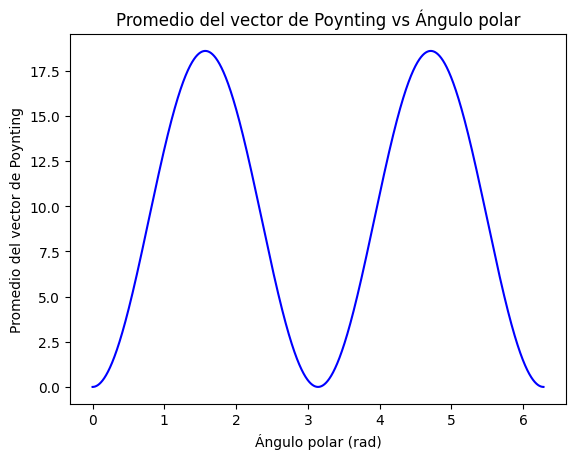

In [69]:
theta = np.linspace(0, 2* np.pi, 10000)
R = np.linspace(1, 50, 10000)  

plt.plot(R, avg_magPoynting(R, np.pi / 2), color='blue')
plt.title('Promedio del vector de Poynting vs Distancia radial (R) en un periodo completo')
plt.xlabel('Distancia radial (m)')
plt.ylabel('Promedio del vector de Poynting')
plt.show()


plt.plot(theta, avg_magPoynting(10, theta), color='blue')
plt.title('Promedio del vector de Poynting vs Ángulo polar')
plt.xlabel('Ángulo polar (rad)')
plt.ylabel('Promedio del vector de Poynting')
plt.show() 




In [ ]:
r_obs = 10.0  # Distancia de observación (m)
dP_dOmega = r_obs**2 * avg_magPoynting(r_obs, theta_plot)

plt.plot(np.degrees(theta_plot), dP_dOmega, color="darkorange")
plt.xlabel("Ángulo polar θ (°)")
plt.ylabel("Potencia radiada por unidad de ángulo sólido (W/sr)")
plt.title("Distribución angular de la potencia radiada")
plt.grid(True)
plt.xlim(0, 180)
plt.show()